# 01 – First Look: New York Airbnb Listings

**Goal:** Verify that the dataset passes our S1 hard gate and take a first look at the data (shape, types, missingness, duplicates, target distribution).

**Data source (provenance)**
- Kaggle: *Airbnb Listings & Reviews* by mysarahmadbhat — https://www.kaggle.com/datasets/mysarahmadbhat/airbnb-listings-reviews
- License: CC0 Public Domain. Original source: Inside Airbnb (via Maven Analytics).
- Files in the zip are dated 2021-08-15 → this is a **historical snapshot**. Our task is to estimate *historical* listing prices, not today's prices.

**Scope:** Only New York City listings (prices are in local currency, so mixing cities would mix currencies). Target variable: `price` (USD per night). Unit of observation: one listing.

In [1]:
# --- Imports and settings ---
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
RANDOM_STATE = 42                      # fixed seed for reproducibility (used later)
DATA_RAW = Path("../data/raw")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
print("pandas", pd.__version__)

pandas 3.0.6


## 1. Load the data
The CSV is **not UTF-8** encoded (some characters fail), so we read it with `latin-1`.

In [2]:
listings_all = pd.read_csv(DATA_RAW / "Listings.csv", encoding="latin-1", low_memory=False)
print("All cities:", listings_all.shape)
listings_all["city"].value_counts()

All cities: (279712, 33)


city
Paris             64690
New York          37012
Sydney            33630
Rome              27647
Rio de Janeiro    26615
Istanbul          24519
Mexico City       20065
Bangkok           19361
Cape Town         19086
Hong Kong          7087
Name: count, dtype: int64

## 2. Keep only New York
Why: one city = one currency and one market.

In [3]:
ny_mask = listings_all["city"].str.contains("new york", case=False, na=False)
df = listings_all.loc[ny_mask].copy()
print("New York shape:", df.shape)
df.head()

New York shape: (37012, 33)


,listing_id,name,host_id,host_since,host_location,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_total_listings_count,host_has_profile_pic,host_identity_verified,neighbourhood,district,city,latitude,longitude,property_type,room_type,accommodates,bedrooms,amenities,price,minimum_nights,maximum_nights,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable
9220,3457770,Cute 1 BR in the Lower East Side,9604972,2013-10-23,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,t,t,Lower East Side,Manhattan,New York,40.72120,-73.98893,Entire apartment,Entire place,3,1.0,"[""Smoke alarm"", ""Essentials"", ""Washer"", ""Dryer...",110,30,1125,80.0,10.0,8.0,8.0,8.0,10.0,10.0,f
9221,4173751,Lovely Apartment in Harlem West,9197440,2013-10-02,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,t,t,Harlem,Manhattan,New York,40.81619,-73.94003,Entire apartment,Entire place,2,NaN,"[""Essentials"", ""Wifi"", ""Heating"", ""Long term s...",99,30,1125,90.0,10.0,9.0,10.0,10.0,9.0,9.0,f
9222,4259427,Appartement en duplex de 3 chambres,21833312,2014-09-27,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,t,t,Crown Heights,Brooklyn,New York,40.67027,-73.94033,Entire apartment,Entire place,6,3.0,"[""Refrigerator"", ""Microwave"", ""Shampoo"", ""Air ...",220,6,1125,87.0,9.0,8.0,10.0,10.0,8.0,8.0,f
9223,4370230,NaN,22686810,2014-10-18,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,t,t,Nolita,Manhattan,New York,40.72046,-73.99550,Entire apartment,Entire place,2,1.0,"[""Smoke alarm"", ""Essentials"", ""Wifi"", ""Heating...",215,30,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
9224,5286096,Amazing Studio-EmpireStateBuilding,3866196,2012-10-14,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,t,t,Midtown,Manhattan,New York,40.74610,-73.98632,Entire apartment,Entire place,3,NaN,"[""Smoke alarm"", ""Washer"", ""Dryer"", ""Wifi"", ""He...",300,30,1125,93.0,9.0,9.0,9.0,10.0,9.0,9.0,f


## 3. Variable overview
Data type, number of distinct values and missing values for every column. This table is the starting point of our variable dictionary (S2).

In [4]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
})
overview

,dtype,n_unique,n_missing,pct_missing
listing_id,int64,37012,0,0.00
name,str,35625,13,0.04
host_id,int64,26765,0,0.00
host_since,str,4000,18,0.05
host_location,str,1316,116,0.31
host_response_time,str,4,18507,50.00
host_response_rate,float64,77,18507,50.00
host_acceptance_rate,float64,98,14633,39.54
host_is_superhost,str,2,18,0.05
host_total_listings_count,float64,79,18,0.05


## 4. Duplicates
One row should be one listing.

In [5]:
print("Duplicate listing_id :", df["listing_id"].duplicated().sum())
print("Fully duplicated rows:", df.duplicated().sum())

Duplicate listing_id : 0
Fully duplicated rows: 0


## 5. Missing values

18 of 33 columns have missing values


,n_missing,pct_missing
host_response_time,18507,50.00
host_response_rate,18507,50.00
host_acceptance_rate,14633,39.54
review_scores_value,10272,27.75
review_scores_location,10272,27.75
review_scores_checkin,10271,27.75
review_scores_accuracy,10259,27.72
review_scores_communication,10257,27.71
review_scores_cleanliness,10248,27.69
review_scores_rating,10235,27.65


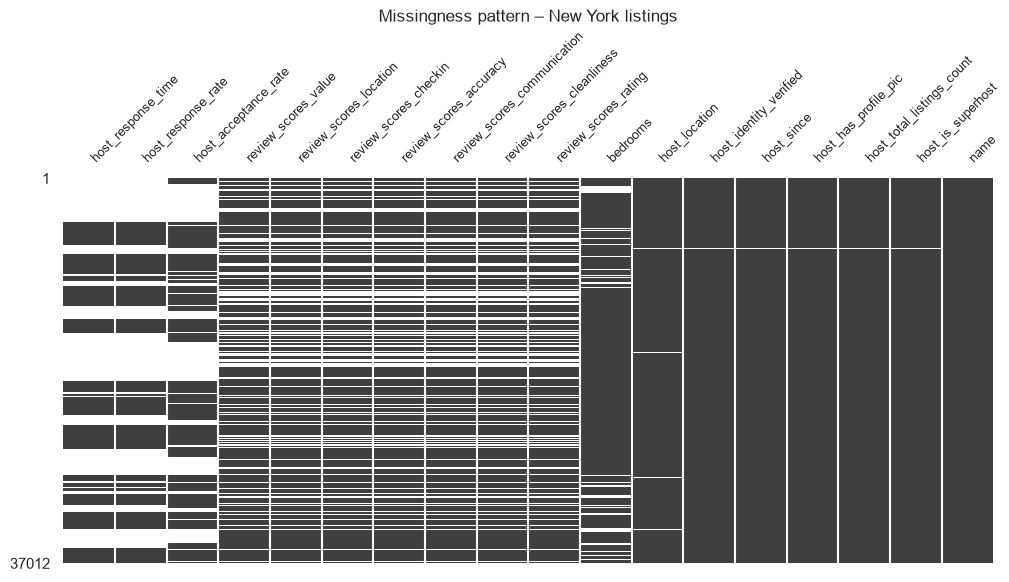

In [6]:
missing = overview.loc[overview["n_missing"] > 0, ["n_missing", "pct_missing"]].sort_values("pct_missing", ascending=False)
print(f"{len(missing)} of {df.shape[1]} columns have missing values")
display(missing)

# Visual pattern of missingness: do columns go missing together?
ax = msno.matrix(df[missing.index], figsize=(12, 5), fontsize=9, sparkline=False)
ax.set_title("Missingness pattern – New York listings")
plt.savefig(FIG_DIR / "01_missingness_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Descriptive statistics

In [7]:
# Continuous / numeric variables
df.describe().T

,count,mean,std,min,25%,50%,75%,max
listing_id,37012.0,2.510589e+07,1.517880e+07,2595.00000,1.103335e+07,2.485448e+07,3.982193e+07,4.803978e+07
host_id,37012.0,9.370949e+07,1.101374e+08,2438.00000,9.643914e+06,4.023649e+07,1.529683e+08,3.870718e+08
host_response_rate,18505.0,8.852559e-01,2.502347e-01,0.00000,9.000000e-01,1.000000e+00,1.000000e+00,1.000000e+00
host_acceptance_rate,22379.0,8.047125e-01,2.808516e-01,0.00000,7.300000e-01,9.400000e-01,1.000000e+00,1.000000e+00
host_total_listings_count,36994.0,2.397416e+01,1.582249e+02,0.00000,1.000000e+00,1.000000e+00,2.000000e+00,2.739000e+03
latitude,37012.0,4.072965e+01,5.471032e-02,40.50868,4.069032e+01,4.072546e+01,4.076248e+01,4.091214e+01
longitude,37012.0,-7.395099e+01,4.829056e-02,-74.23986,-7.398381e+01,-7.395579e+01,-7.393372e+01,-7.371087e+01
accommodates,37012.0,2.797633e+00,1.845570e+00,0.00000,2.000000e+00,2.000000e+00,4.000000e+00,1.600000e+01
bedrooms,33404.0,1.316399e+00,7.220938e-01,1.00000,1.000000e+00,1.000000e+00,1.000000e+00,2.100000e+01
price,37012.0,1.428422e+02,2.757410e+02,0.00000,6.000000e+01,9.900000e+01,1.510000e+02,1.000000e+04


In [8]:
# Main categorical variables (counts and shares, missing included)
for col in ["district", "room_type", "host_is_superhost", "instant_bookable", "host_response_time"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False).to_frame("count")
            .assign(share=lambda t: (t["count"] / t["count"].sum()).round(3)))
    print()
print("property_type – top 10:")
df["property_type"].value_counts().head(10)

--- district ---
               count  share
district                   
Manhattan      16553  0.447
Brooklyn       14474  0.391
Queens          4704  0.127
Bronx            992  0.027
Staten Island    289  0.008

--- room_type ---
              count  share
room_type                 
Entire place  19397  0.524
Private room  16630  0.449
Shared room     686  0.019
Hotel room      299  0.008

--- host_is_superhost ---
                   count  share
host_is_superhost              
f                  30023  0.811
t                   6971  0.188
NaN                   18  0.000

--- instant_bookable ---
                  count  share
instant_bookable              
f                 25972  0.702
t                 11040  0.298

--- host_response_time ---
                    count  share
host_response_time              
NaN                 18507  0.500
within an hour      10143  0.274
within a few hours   3937  0.106
within a day         3039  0.082
a few days or more   1386  0.037

property_

property_type
Entire apartment               15506
Private room in apartment      12037
Private room in house           1897
Private room in townhouse       1044
Entire condominium               983
Entire house                     949
Entire loft                      628
Entire townhouse                 589
Shared room in apartment         501
Private room in condominium      477
Name: count, dtype: int64

## 7. Target: `price`
Checks: is it numeric, are there zero/negative values, how extreme is the right tail?

In [9]:
price = pd.to_numeric(df["price"], errors="coerce")
print("Non-numeric prices :", price.isna().sum() - df["price"].isna().sum())
print("Missing prices     :", df["price"].isna().sum())
print("Prices <= 0        :", (price <= 0).sum())
price.quantile([0, 0.01, 0.25, 0.5, 0.75, 0.9, 0.99, 0.999, 1]).to_frame("price_usd")

Non-numeric prices : 0
Missing prices     : 0
Prices <= 0        : 28


,price_usd
0.000,0.0
0.010,25.0
0.250,60.0
0.500,99.0
0.750,151.0
0.900,250.0
0.990,850.0
0.999,3197.8
1.000,10000.0


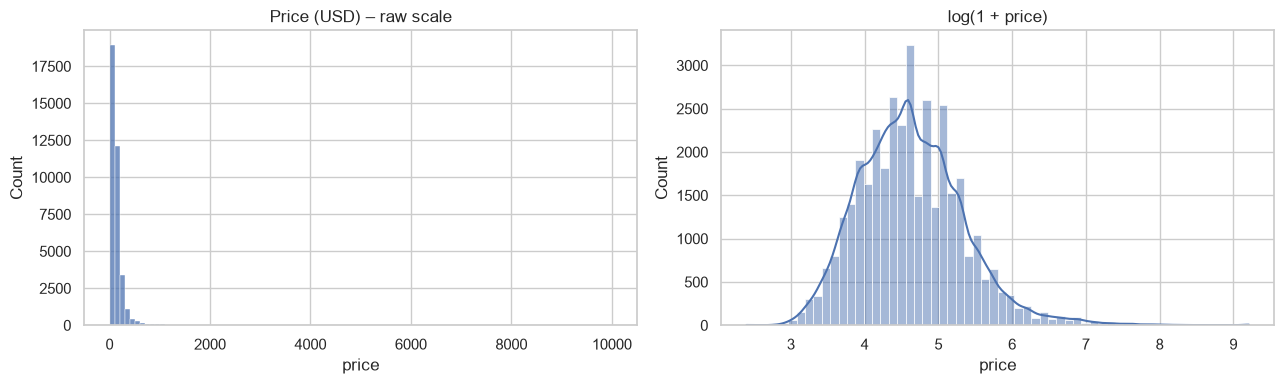

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(price.dropna(), bins=100, ax=axes[0])
axes[0].set_title("Price (USD) – raw scale")
sns.histplot(np.log1p(price[price > 0]), bins=60, kde=True, ax=axes[1])
axes[1].set_title("log(1 + price)")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_price_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Price by room type and by borough
Log scale on the y-axis because of the long right tail.

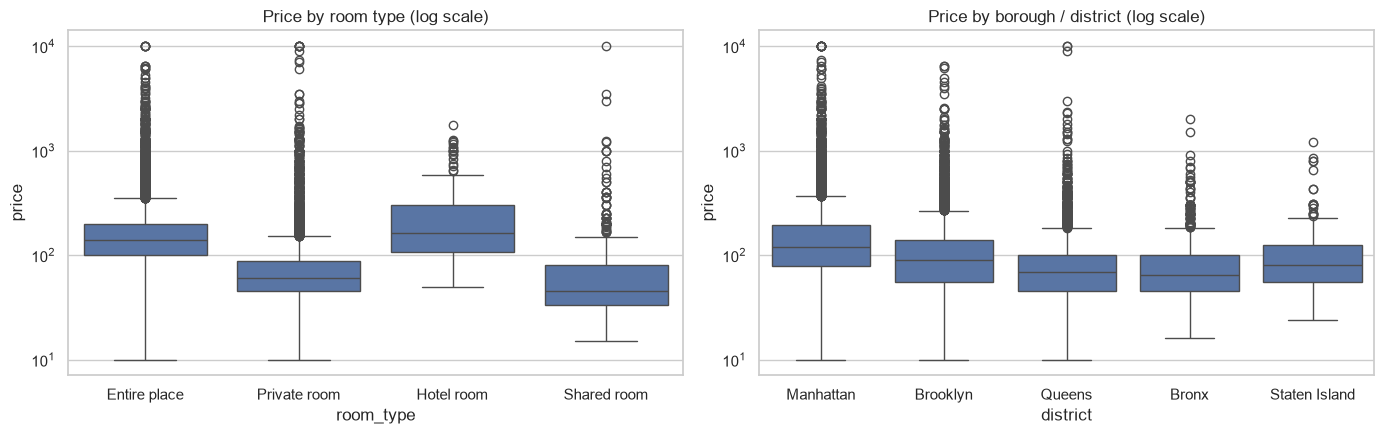

,n_listings,median_price
neighbourhood,,
Williamsburg,2731,100.0
Bedford-Stuyvesant,2711,80.0
Harlem,1972,80.0
Bushwick,1678,60.0
Hell's Kitchen,1503,130.0
Upper West Side,1454,135.5
Midtown,1444,149.0
Upper East Side,1342,125.0
East Village,1313,129.0


In [11]:
plot_df = df.assign(price=price).query("price > 0")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=plot_df, x="room_type", y="price", ax=axes[0])
axes[0].set_yscale("log"); axes[0].set_title("Price by room type (log scale)")
sns.boxplot(data=plot_df, x="district", y="price", ax=axes[1])
axes[1].set_yscale("log"); axes[1].set_title("Price by borough / district (log scale)")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_price_by_roomtype_district.png", dpi=120, bbox_inches="tight")
plt.show()

# Top 15 neighbourhoods by number of listings, with median price
(plot_df.groupby("neighbourhood")["price"]
        .agg(n_listings="size", median_price="median")
        .sort_values("n_listings", ascending=False)
        .head(15))

## 9. Candidate classification target: `host_is_superhost`
We check class balance before committing to it in S2.

In [12]:
df["host_is_superhost"].value_counts(dropna=False, normalize=True).round(3)

host_is_superhost
f      0.811
t      0.188
NaN    0.000
Name: proportion, dtype: float64

## 10. Review activity over time (EDA only)
Reviews are **not** used as model features yet (leakage risk). Here they only show how activity changed over time.

All reviews: 5373143 | New York reviews: 847727
Date range: 2009-04-23 → 2021-02-05


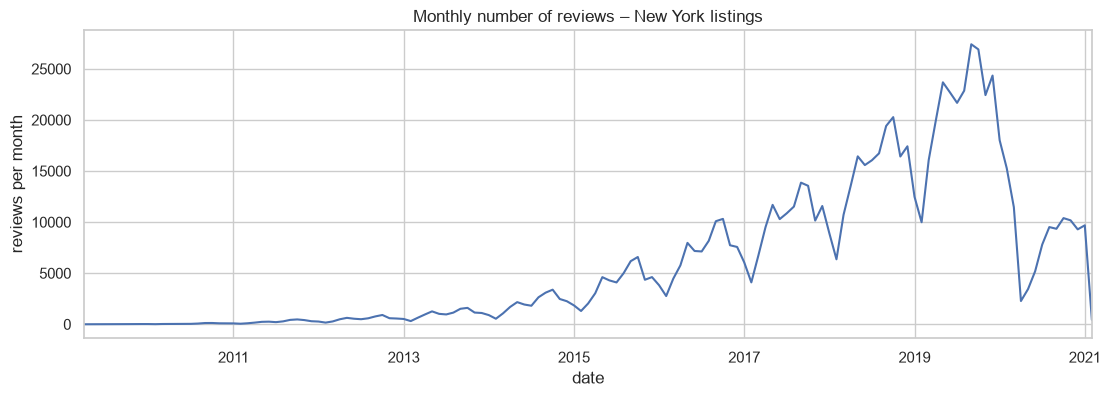

In [13]:
reviews = pd.read_csv(DATA_RAW / "Reviews.csv", usecols=["listing_id", "date"],
                      encoding="latin-1", parse_dates=["date"])
ny_reviews = reviews[reviews["listing_id"].isin(df["listing_id"])]
print("All reviews:", len(reviews), "| New York reviews:", len(ny_reviews))
print("Date range:", ny_reviews["date"].min().date(), "→", ny_reviews["date"].max().date())

monthly = ny_reviews.set_index("date").resample("MS").size()
ax = monthly.plot(figsize=(13, 4), title="Monthly number of reviews – New York listings")
ax.set_ylabel("reviews per month")
plt.savefig(FIG_DIR / "01_monthly_reviews.png", dpi=120, bbox_inches="tight")
plt.show()

## 11. Hard-gate check (S1)
Conditions agreed with the reviewer before we confirm the dataset.

In [14]:
gate = {
    "rows >= 10,000": len(df) >= 10_000,
    "price numeric for >= 99% of rows": price.notna().mean() >= 0.99,
    "no duplicate listing_id": df["listing_id"].duplicated().sum() == 0,
    ">= 3 columns with missing values": (overview["n_missing"] > 0).sum() >= 3,
}
for k, v in gate.items():
    print(f"{'PASS' if v else 'FAIL'}  {k}")

PASS  rows >= 10,000
PASS  price numeric for >= 99% of rows
PASS  no duplicate listing_id
PASS  >= 3 columns with missing values


## 12. Data-quality flags
Quick checks on suspicious values found in the tables above. Nothing is changed here; decisions are taken in S7 (preprocessing).

In [15]:
flags = {
    "price == 0 (by room_type)": df.loc[df["price"] == 0, "room_type"].value_counts().to_dict(),
    "accommodates == 0": int((df["accommodates"] == 0).sum()),
    "maximum_nights > 10,000": int((df["maximum_nights"] > 10_000).sum()),
    "maximum_nights max": int(df["maximum_nights"].max()),
    "bedrooms min (non-missing)": df["bedrooms"].min(),
}
for k, v in flags.items():
    print(f"{k:32s}: {v}")

# Where is `bedrooms` missing? (hypothesis: studios coded as NaN instead of 0)
print("\nbedrooms missing – top property types:")
print(df.loc[df["bedrooms"].isna(), "property_type"].value_counts().head(5))

# Are review scores missing because the listing has no reviews?
n_reviews = ny_reviews.groupby("listing_id").size()
has_review = df["listing_id"].isin(n_reviews.index)
print("\nListings with >= 1 review :", has_review.sum(), "of", len(df))
print("review_scores_rating missing | no review :", df.loc[~has_review, "review_scores_rating"].isna().mean().round(3))
print("review_scores_rating missing | has review:", df.loc[has_review, "review_scores_rating"].isna().mean().round(3))

price == 0 (by room_type)       : {'Hotel room': 28}
accommodates == 0               : 13
maximum_nights > 10,000         : 3
maximum_nights max              : 2147483647
bedrooms min (non-missing)      : 1.0

bedrooms missing – top property types:
property_type
Entire apartment             2646
Private room in apartment     243
Entire condominium            119
Entire loft                   110
Entire serviced apartment      68
Name: count, dtype: int64

Listings with >= 1 review : 27489 of 37012
review_scores_rating missing | no review : 1.0
review_scores_rating missing | has review: 0.026


## 13. Preliminary dataset story
*Preliminary observations, not statistical conclusions. Each one is checked properly in later stages.*

1. **The dataset passes the S1 hard gate.** New York has **37,012 listings × 33 columns**, no duplicate `listing_id`, and `price` is numeric for every row. It is the 2nd largest city in the file after Paris.
2. **The market is concentrated and skewed.** Manhattan (44.7%) and Brooklyn (39.1%) hold ~84% of listings. Price is strongly right-skewed: median **\$99**, 75th percentile \$151, 99th percentile \$850, maximum \$10,000 → we will model `log(1 + price)` and treat the tail in S7.
3. **Missingness is real and has structure.** 18 of 33 columns have missing values. `host_response_time` and `host_response_rate` are missing together for exactly 50% of listings; the 7 `review_scores_*` columns are missing for ~27.7% — mostly listings that never received a review (structural, not random). `bedrooms` is missing for 9.75%, mostly "Entire apartment" listings, and the smallest observed value is 1 → studios may be coded as missing instead of 0. These patterns shape the S7 imputation strategy.
4. **There are clear data errors to handle.** 28 listings have price = \$0 (all hotel rooms), 13 listings accommodate 0 guests, and `maximum_nights` reaches 2,147,483,647 (a placeholder value).
5. **The snapshot reflects the COVID period.** Monthly New York reviews fell from about 15k (Feb 2020) to about 2.3k (Apr 2020), then recovered only to about 9–10k per month (Aug 2020 – Jan 2021); the last review is dated 2021-02-05. The median `minimum_nights` is 30, i.e. many listings target long stays. Our results describe this historical market, not today's.

**Classification target check:** `host_is_superhost` is 18.8% "t" vs 81.1% "f" → usable, but imbalanced (we will need stratified splits and metrics such as F1 / ROC-AUC).

**Still to investigate:** price outlier rules, whether the studio hypothesis for `bedrooms` holds, host-level overlap between train and test sets, and which review-based features are safe from leakage.